# De los datos diarios a la predicción de PM10

Este recorrido explica el proyecto de predicción de PM10 usando tres estaciones de Madrid.
La pregunta principal es cuánto PM10 se observará el día siguiente. Después revisamos los
avisos de comienzo de días elevados y su utilidad bajo distintos costes relativos.

Una fila diaria representa una estación y una fecha. PM10 se expresa en µg/m³.
Una fila supervisada añade la fecha objetivo y las variables conocidas hasta la última observación.

El notebook reconstruye las variables con los mapeadores, repite el ajuste y la validación de
2017–2023 en memoria y consulta los artefactos congelados para explicar los resultados de 2024.
La clasificación de 2025 y el complemento sanitario se recorren a partir de sus resultados guardados.

## Antes de empezar

Desde la raíz, instala las dependencias

    ./.venv/Scripts/python.exe -m pip install -r notebooks/requirements.txt

Abre este archivo en VS Code con las extensiones de Python y Jupyter y selecciona
el ejecutable de .venv como kernel. Ejecuta las celdas en orden.
Las tablas preparadas, los modelos y los resultados del proyecto deben estar presentes.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys

ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "pm10_data/config.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Abre el notebook dentro de la carpeta del proyecto.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pm10_data.mappers.pm10_forecast import PM10ForecastMapper, label_elevated_pm10
from pm10_data.models.artifacts import load_model
from pm10_data.models.factory import FEATURES, create_models
from pm10_data.evaluation.pm10_regression import split_dataset, evaluate_models, calculate_metrics
from pm10_data.pipelines.evaluate_pm10_business import onset_counts, scenario_costs

pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18, "axes.axisbelow": True,
})
display(pd.Series({
    name: importlib.metadata.version(name)
    for name in ["numpy", "pandas", "scikit-learn", "joblib", "matplotlib"]
}, name="Versión utilizada").to_frame())

,Versión utilizada
numpy,2.3.5
pandas,3.0.1
scikit-learn,1.9.1
joblib,1.6.0
matplotlib,3.11.2


## 1. Inspeccionar la tabla diaria

La tabla procede de la preparación de datos MITECO de 2017–2024.
La columna pm10_valido conserva la concentración aceptada y deja ausente una medición que no supera
los controles de calidad. Los códigos de estación se leen como texto para conservar su formato.

Consulta [fuentes y formatos](../docs/15_fuentes_endpoints_formatos.md) y
[trazabilidad de los mapeadores](../docs/16_trazabilidad_mappers_tablas.md).

In [2]:
daily_path = ROOT / "data/interim/daily_pollution/pm10_madrid_diario_2017_2024.csv"
daily = pd.read_csv(daily_path, dtype={"codigo_estacion": "string"}, parse_dates=["fecha"])
assert not daily.duplicated(["codigo_estacion", "fecha"]).any()
coverage = daily.groupby(["codigo_estacion", "NOMBRE"], as_index=False).agg(
    dias=("fecha", "size"), dias_validos=("pm10_valido", "count"),
    inicio=("fecha", "min"), fin=("fecha", "max"),
)
coverage["dias_ausentes"] = coverage.dias - coverage.dias_validos
display(coverage)
display(daily[["codigo_estacion", "fecha", "concentracion", "estado", "pm10_valido"]].head())
display(daily.loc[daily.pm10_valido.isna(),
                  ["codigo_estacion", "fecha", "estado", "pm10_valido"]].head())

,codigo_estacion,NOMBRE,dias,dias_validos,inicio,fin,dias_ausentes
0,28079060,TRES OLIVOS,2922,2895,2017-01-01,2024-12-31,27
1,28080003,MAJADAHONDA,2922,2908,2017-01-01,2024-12-31,14
2,28133002,SAN MARTIN DE VALDEIGLESIAS,2922,2902,2017-01-01,2024-12-31,20


,codigo_estacion,fecha,concentracion,estado,pm10_valido
0,28079060,2017-01-01,17.000,valida,17.000
1,28079060,2017-01-02,14.000,valida,14.000
2,28079060,2017-01-03,26.000,valida,26.000
3,28079060,2017-01-04,26.000,valida,26.000
4,28079060,2017-01-05,14.000,valida,14.000


,codigo_estacion,fecha,estado,pm10_valido
921,28079060,2019-07-11,cobertura_horaria_insuficiente,NaN
1158,28079060,2020-03-04,cobertura_horaria_insuficiente,NaN
1590,28079060,2021-05-10,sin_registro,NaN
1591,28079060,2021-05-11,cobertura_horaria_insuficiente,NaN
1615,28079060,2021-06-04,cobertura_horaria_insuficiente,NaN


## 2. Construir las variables con el mapeador

PM10ForecastMapper crea los retardos, las medias móviles y el calendario.
La media de 14 días exige 14 observaciones válidas consecutivas. Un hueco puede afectar a
varias filas futuras porque sus ventanas lo incluyen.

La variable pm10_t corresponde al día previo a la fecha objetivo. La variable pm10_t_menos_6
corresponde al mismo día de la semana del objetivo una semana antes.
El objetivo se desplaza hacia el día siguiente. El umbral de clasificación es el percentil 90
de los objetivos disponibles de entrenamiento y se mantiene fijo.

In [3]:
supervised = PM10ForecastMapper().transform(daily)
supervised, threshold = label_elevated_pm10(supervised)
complete = supervised.loc[supervised.fila_utilizable].copy()
keys = ["codigo_estacion", "fecha_objetivo"]
saved_complete = pd.read_csv(
    ROOT / "data/interim/pm10_prediction/tabla_modelos_completa.csv",
    dtype={"codigo_estacion": "string"},
    parse_dates=["fecha_objetivo", "fecha_ultima_observacion"],
)
comparison_columns = keys + FEATURES[:-1] + ["pm10_objetivo", "particion"]
pd.testing.assert_frame_equal(
    complete[comparison_columns].sort_values(keys).reset_index(drop=True),
    saved_complete[comparison_columns].sort_values(keys).reset_index(drop=True),
    check_dtype=False, check_exact=False, atol=1e-10, rtol=1e-10,
)
assert threshold == 27
print(f"Umbral fijo: PM10 > {threshold:g} µg/m³")
display(complete[[
    "codigo_estacion", "fecha_ultima_observacion", "fecha_objetivo",
    "pm10_t", "pm10_t_menos_1", "media_7_dias", "pm10_objetivo",
]].head())
coverage_by_partition = supervised.loc[supervised.particion.ne("fuera_periodo")].groupby(
    "particion", as_index=False
).agg(filas=("fecha_objetivo", "size"), utilizables=("fila_utilizable", "sum"))
coverage_by_partition["excluidas"] = coverage_by_partition.filas - coverage_by_partition.utilizables
display(coverage_by_partition)

Umbral fijo: PM10 > 27 µg/m³


,codigo_estacion,fecha_ultima_observacion,fecha_objetivo,pm10_t,pm10_t_menos_1,media_7_dias,pm10_objetivo
13,28079060,2017-01-14,2017-01-15,6.600,6.300,12.629,6.900
14,28079060,2017-01-15,2017-01-16,6.900,6.600,12.043,8.500
15,28079060,2017-01-16,2017-01-17,8.500,6.900,11.114,3.100
16,28079060,2017-01-17,2017-01-18,3.100,8.500,7.986,8.800
17,28079060,2017-01-18,2017-01-19,8.800,3.100,8.029,13.000


,particion,filas,utilizables,excluidas
0,entrenamiento,6570,6096,474
1,prueba_reservada,1098,1013,85
2,validacion,1095,1039,56


## 3. Separar entrenamiento, validación y prueba por fecha objetivo

Entrenamos con objetivos de 2017–2022 y validamos con 2023. La función compartida
split_dataset comprueba fechas, estaciones y horizonte de un día. El escalador y la
codificación de estación se ajustan dentro de cada pipeline usando entrenamiento.
La prueba de 2024 se consulta más adelante con el modelo congelado.

La emisión a medianoche UTC es una hipótesis retrospectiva. Antes de un piloto habría que
medir cuándo llega cada dato y evaluar variables disponibles a la hora de emisión propuesta.

In [4]:
training, validation = split_dataset(complete)
test = complete.loc[complete.particion.eq("prueba_reservada")].copy()
display(pd.DataFrame([
    {"conjunto": name, "filas": len(frame),
     "primer_objetivo": frame.fecha_objetivo.min(),
     "ultimo_objetivo": frame.fecha_objetivo.max()}
    for name, frame in [("entrenamiento", training), ("validación", validation), ("prueba", test)]
]))
assert training.fecha_objetivo.max() < validation.fecha_objetivo.min()
assert validation.fecha_objetivo.max() < test.fecha_objetivo.min()
assert (complete.fecha_objetivo - complete.fecha_ultima_observacion).eq(pd.Timedelta(days=1)).all()

,conjunto,filas,primer_objetivo,ultimo_objetivo
0,entrenamiento,6096,2017-01-15,2022-12-31
1,validación,1039,2023-01-01,2023-12-31
2,prueba,1013,2024-01-01,2024-12-31


## 4. Ajustar y comparar en validación de 2023

Ridge combina las variables linealmente y regulariza sus coeficientes. Random Forest combina
árboles y permite relaciones no lineales. Las referencias repiten el último PM10, la media
semanal o el valor de una semana antes.

MAE expresa el tamaño medio del error en µg/m³. RMSE da más peso a errores grandes y el sesgo
indica si la predicción queda por encima o por debajo del observado en promedio.
La restricción de concentración no negativa se aplica antes de evaluar.

,modelo,n,mae,sesgo,negativas_corregidas,rmse
4,ridge,1039,4.826,0.241,0,7.510
2,random_forest,1039,4.945,0.495,0,7.870
1,persistencia,1039,5.140,0.064,0,8.352
0,media_movil_7d,1039,6.525,-0.018,0,9.970
3,referencia_semanal,1039,8.751,-0.159,0,13.362


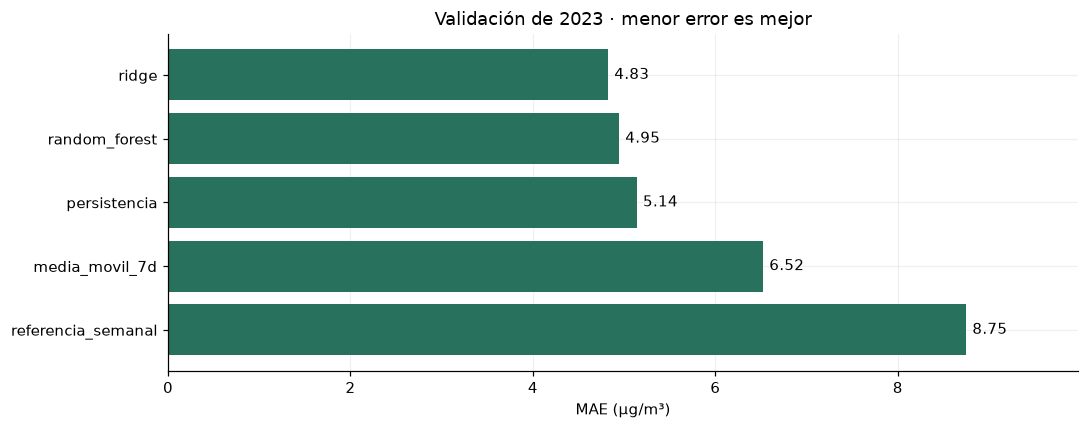

In [5]:
models = create_models()
validation_predictions = evaluate_models(training, validation, models)
validation_metrics = calculate_metrics(validation_predictions, ["modelo"])
display(validation_metrics.sort_values("mae"))
saved_metrics = pd.read_csv(ROOT / "output/pm10_regression_validation/metricas_validacion_2023.csv")
metric_columns = ["modelo", "n", "mae", "rmse", "sesgo"]
pd.testing.assert_frame_equal(
    validation_metrics[metric_columns].sort_values("modelo").reset_index(drop=True),
    saved_metrics[metric_columns].sort_values("modelo").reset_index(drop=True),
    check_dtype=False, check_exact=False, atol=1e-8, rtol=1e-8,
)
ordered = validation_metrics.sort_values("mae")
fig, ax = plt.subplots()
bars = ax.barh(ordered.modelo, ordered.mae, color="#28715c")
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.invert_yaxis()
ax.set(xlabel="MAE (µg/m³)", title="Validación de 2023 · menor error es mejor")
ax.set_xlim(0, ordered.mae.max() * 1.14)
fig.tight_layout()
plt.show()

Ridge obtuvo el menor MAE en la validación registrada. La mejora respecto a persistencia
debe examinarse también por estación y en episodios elevados.

## 5. Reproducir las predicciones del Ridge congelado en 2024

Comprobamos las huellas del artefacto y de la tabla que figuran en el protocolo.
La predicción se calcula con ese artefacto y se contrasta con el CSV de resultados.
El ajuste de la celda anterior permanece en memoria para la validación didáctica.
Esta comparación reproduce una prueba ya realizada cuyo resultado forma parte de la evaluación retrospectiva.

In [6]:
protocol_path = ROOT / "docs/reference/pm10_final_protocol.json"
protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
for entry in [protocol["entradas"]["ridge"], protocol["entradas"]["tabla"]]:
    path = ROOT / entry["ruta"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == entry["sha256"], path.name
frozen = load_model(ROOT / protocol["entradas"]["ridge"]["ruta"])
assert frozen["configuracion"]["fecha_maxima_entrenamiento"] == "2022-12-31"
frozen_features = frozen["configuracion"]["variables"]
test = test.sort_values(keys).reset_index(drop=True)
prediction_2024 = np.maximum(0, frozen["pipeline"].predict(test[frozen_features]))
saved_2024 = pd.read_csv(
    ROOT / "output/pm10_final_2024/predicciones_regresion.csv",
    dtype={"codigo_estacion": "string"}, parse_dates=["fecha_objetivo"],
)
saved_ridge = saved_2024.loc[saved_2024.modelo.eq("ridge")].sort_values(keys).reset_index(drop=True)
pd.testing.assert_frame_equal(test[keys], saved_ridge[keys], check_dtype=False)
np.testing.assert_allclose(prediction_2024, saved_ridge.prediccion, rtol=1e-10, atol=1e-10)
display(pd.read_csv(ROOT / "output/pm10_final_2024/metricas_regresion.csv"))
print(f"Predicciones contrastadas: {len(test)}")

,tramo,modelo,n,mae,sesgo,negativas_corregidas,rmse
0,elevado,persistencia,107,18.252,-9.505,0,25.630
1,elevado,ridge,107,19.562,-17.390,0,26.871
2,resto,persistencia,906,4.617,1.119,0,8.721
3,resto,ridge,906,4.351,1.841,0,6.116
4,todos,persistencia,1013,6.058,-0.003,0,11.722
5,todos,ridge,1013,5.958,-0.190,0,10.475


Predicciones contrastadas: 1013


## 6. Examinar un pico y sus errores

El 31 de octubre de 2024 permite observar una infraestimación importante en Tres Olivos.
El gráfico conserva el calendario y deja huecos cuando una fecha queda fuera de la muestra.
La línea de 27 µg/m³ representa el umbral estadístico de este trabajo.

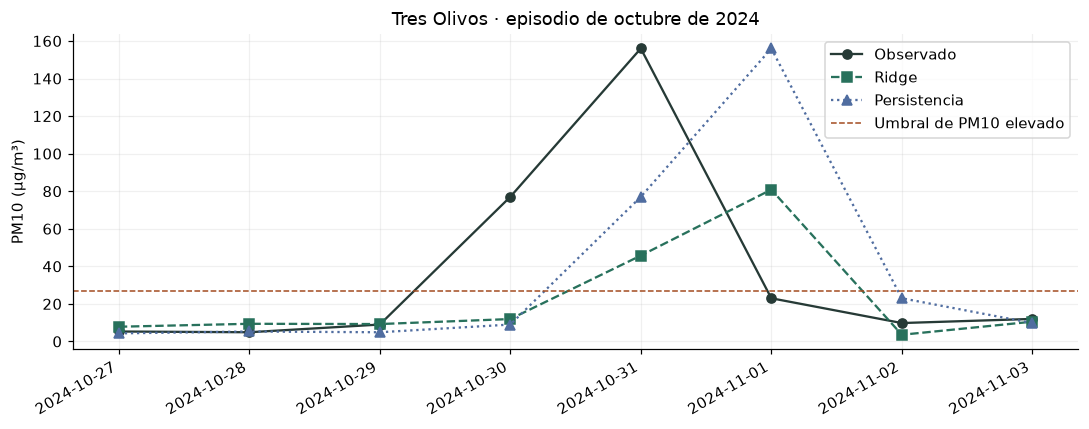

,modelo,pm10_objetivo,prediccion,error_absoluto
282,ridge,156.000,45.726,110.274
1295,persistencia,156.000,77.000,79.000


In [7]:
station = "28079060"
target_date = pd.Timestamp("2024-10-31")
period = pd.date_range("2024-10-27", "2024-11-03")
selected = saved_2024.loc[
    saved_2024.codigo_estacion.eq(station) & saved_2024.fecha_objetivo.isin(period)
]
wide = selected.pivot(index="fecha_objetivo", columns="modelo", values="prediccion").reindex(period)
observed = selected.drop_duplicates("fecha_objetivo").set_index("fecha_objetivo").pm10_objetivo.reindex(period)
fig, ax = plt.subplots()
ax.plot(period, observed, "o-", color="#263a36", label="Observado")
ax.plot(period, wide.ridge, "s--", color="#28715c", label="Ridge")
ax.plot(period, wide.persistencia, "^:", color="#506da0", label="Persistencia")
ax.axhline(threshold, color="#a34c20", linestyle="--", linewidth=1, label="Umbral de PM10 elevado")
ax.set(ylabel="PM10 (µg/m³)", title="Tres Olivos · episodio de octubre de 2024")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
display(selected.loc[selected.fecha_objetivo.eq(target_date),
                     ["modelo", "pm10_objetivo", "prediccion", "error_absoluto"]])

## 7. Interpretar variables y descomponer una predicción

Para Ridge multiplicamos cada entrada transformada por su coeficiente y añadimos el
intercepto. La explicación reconstruye la predicción antes de limitarla a cero.
Las variables numéricas están estandarizadas y los indicadores de estación valen cero o uno.

En Random Forest usamos la importancia por reducción de impureza del entrenamiento.
Su valor expresa la proporción de reducción atribuida a una variable y carece de signo.
Los retardos y las medias están relacionados, por lo que sus pesos deben interpretarse conjuntamente.
Consulta [explicabilidad y límites](../docs/31_explicabilidad_pm10.md).

Intercepto 15.401 + aportaciones 30.325 = predicción 45.726 µg/m³


,variable,valor_transformado,coeficiente,aportacion
0,numeric__pm10_t,4.411,6.937,30.601
7,numeric__desviacion_7_dias,2.025,-2.464,-4.989
4,numeric__media_3_dias,1.339,2.030,2.718
1,numeric__pm10_t_menos_1,-0.459,-1.928,0.886
8,numeric__semana_sin,0.617,0.851,0.525
5,numeric__media_7_dias,0.274,1.620,0.444
9,numeric__semana_cos,-1.274,-0.258,0.328
10,numeric__mes_sin,-1.419,0.184,-0.261
2,numeric__pm10_t_menos_2,-0.753,-0.160,0.120
12,station__codigo_estacion_28079060,1.000,-0.059,-0.059


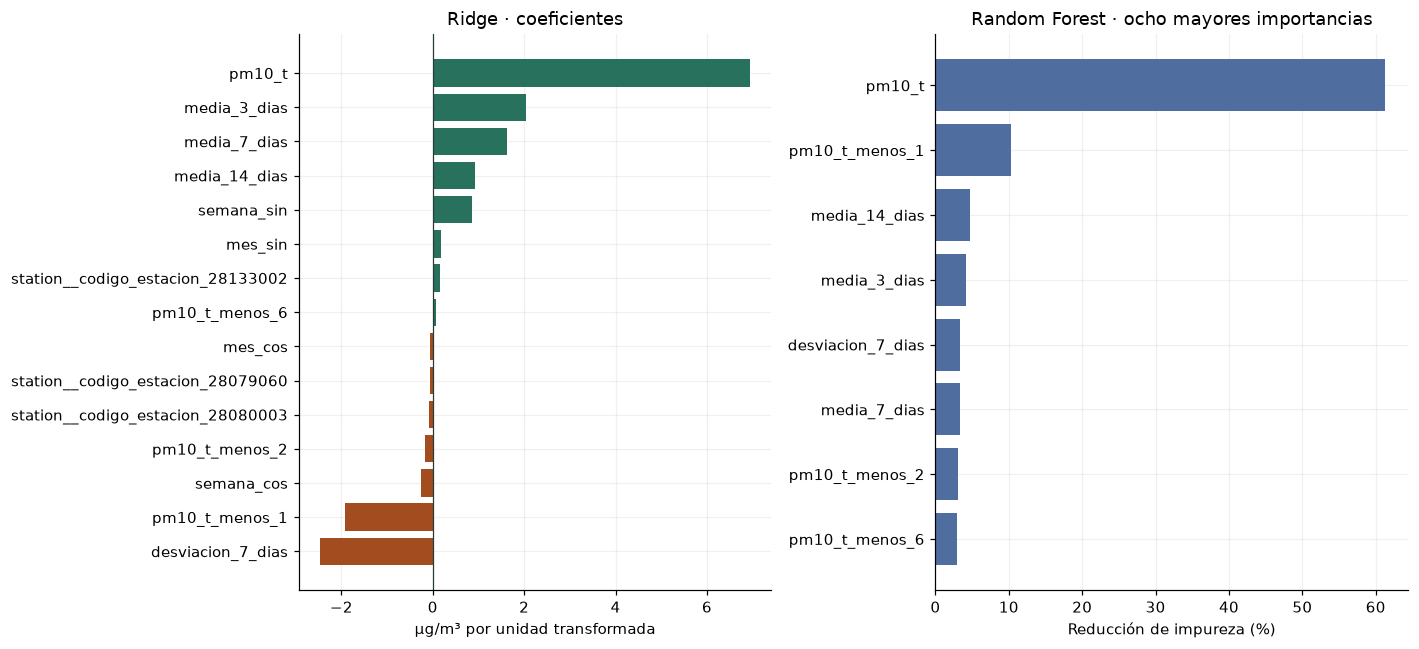

In [8]:
case = test.loc[test.codigo_estacion.eq(station) & test.fecha_objetivo.eq(target_date)]
assert len(case) == 1
explanation = frozen["pipeline"].explain_predictions(case[frozen_features])
local = pd.DataFrame({
    "variable": explanation["names"],
    "valor_transformado": explanation["transformed"][0],
    "coeficiente": explanation["coefficients"],
    "aportacion": explanation["contributions"][0],
})
reconstructed = explanation["intercept"] + local.aportacion.sum()
np.testing.assert_allclose(reconstructed, explanation["predictions"][0], atol=1e-10)
print(f"Intercepto {explanation['intercept']:.3f} + aportaciones {local.aportacion.sum():.3f}"
      f" = predicción {reconstructed:.3f} µg/m³")
display(local.sort_values("aportacion", key=abs, ascending=False))
coefficients = frozen["pipeline"].feature_details().sort_values("coeficiente")
forest_importance = models["random_forest"].feature_details().head(8).sort_values("importancia_impureza")
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(
    coefficients.variable_transformada.str.replace("numeric__", "", regex=False),
    coefficients.coeficiente,
    color=np.where(coefficients.coeficiente.ge(0), "#28715c", "#a34c20"),
)
axes[0].axvline(0, color="#263a36", linewidth=0.8)
axes[0].set(title="Ridge · coeficientes", xlabel="µg/m³ por unidad transformada")
axes[1].barh(
    forest_importance.variable_transformada.str.replace("numeric__", "", regex=False),
    100 * forest_importance.importancia_impureza, color="#506da0",
)
axes[1].set(title="Random Forest · ocho mayores importancias", xlabel="Reducción de impureza (%)")
fig.tight_layout()
plt.show()

## Incertidumbre de la diferencia de MAE

El bootstrap por bloques remuestrea fechas consecutivas y mantiene juntas las estaciones. Los intervalos describen la diferencia de MAE de los modelos congelados en 2024. Se utilizan 5.000 réplicas por longitud y se compara el bloque principal de 14 días con 7 y 28 días.

La tabla siguiente lee los intervalos exportados. Todos incluyen cero, por lo que este diagnóstico deja incierta la dirección de la mejora. La estacionalidad, los huecos y el uso de un solo año limitan su interpretación. [Método, supuestos y reproducción](../docs/36_incertidumbre_pm10.md).

In [9]:
intervals = pd.read_csv(ROOT / "output/pm10_bootstrap/intervalos.csv", dtype={"station": "string"})
display(intervals.loc[intervals.station.eq("todas"), ["block_days", "n", "estimate", "lower", "upper", "includes_zero"]])
assert intervals.includes_zero.all()
global_estimate = intervals.loc[intervals.station.eq("todas"), "estimate"]
expected_difference = (saved_ridge.prediccion - saved_ridge.pm10_objetivo).abs().mean() - saved_2024.loc[saved_2024.modelo.eq("persistencia"), "error_absoluto"].mean()
np.testing.assert_allclose(global_estimate, expected_difference, atol=1e-10)

,block_days,n,estimate,lower,upper,includes_zero
0,7,1013,-0.099,-0.609,0.326,True
4,14,1013,-0.099,-0.565,0.288,True
8,28,1013,-0.099,-0.546,0.294,True


## 8. Revisar la clasificación de comienzos de 2025

La comparación meteorológica usa dos logísticas entrenadas con las mismas filas de
2021–2022 y cortes elegidos en 2023. Sus probabilidades y decisiones de 2025 ya están guardadas.
La meteorología procede de previsiones archivadas y el PM10 observado de horas verificadas de la EEA.

Un comienzo ocurre cuando el día anterior estaba en 27 µg/m³ o menos y el objetivo supera ese umbral.
Aquí contamos únicamente los 891 casos de ese contexto. Los recuentos de falsas alarmas de
esta tabla tienen ese denominador. Las [métricas generales](../docs/25_prueba_meteorologia_2025.md)
también incluyen las continuaciones de episodios.

In [10]:
classification_path = ROOT / "output/pm10_weather_test_2025/predicciones_2025.csv"
classification = pd.read_csv(
    classification_path, dtype={"codigo_estacion": "string"}, parse_dates=["fecha_objetivo"],
)
classification_records = pd.read_csv(classification_path, dtype=str).to_dict("records")
counts = onset_counts(classification_records)
display(pd.DataFrame(counts))
example = classification.loc[
    classification.codigo_estacion.eq("28079060")
    & classification.fecha_objetivo.eq("2025-08-05"),
    ["modelo", "pm10_t", "pm10_objetivo", "probabilidad_elevado", "aviso"],
]
display(example)

,modelo,casos,inicios_reales,inicios_detectados,inicios_omitidos,falsas_alarmas,avisos
0,persistencia,891,27,0,27,0,0
1,logistica_sin_meteo,891,27,6,21,13,19
2,logistica_con_meteo,891,27,9,18,18,27


,modelo,pm10_t,pm10_objetivo,probabilidad_elevado,aviso
186,persistencia,24.417,42.333,NaN,0
1189,logistica_sin_meteo,24.417,42.333,0.159,0
2192,logistica_con_meteo,24.417,42.333,0.212,1


## 9. Relacionar avisos y costes relativos

Tomamos una falsa alarma como una unidad de coste. El parámetro r indica cuánto cuesta omitir
un comienzo respecto a esa unidad. Los escenarios r = 1, 2 y 5 son supuestos de sensibilidad.
Se mantienen los modelos y cortes de la prueba.

El coste se obtiene sumando falsas alarmas y r multiplicado por los comienzos omitidos.
Con estos recuentos, la versión con meteorología resulta más barata que persistencia cuando
r supera 2. En r = 2 empatan. Consulta [supuestos y alcance](../docs/30_metricas_negocio_pm10.md).

modelo,logistica_con_meteo,logistica_sin_meteo,persistencia
escenario,,,
costes_iguales,36,34,27
omision_doble,54,55,54
omision_quintuple,108,118,135


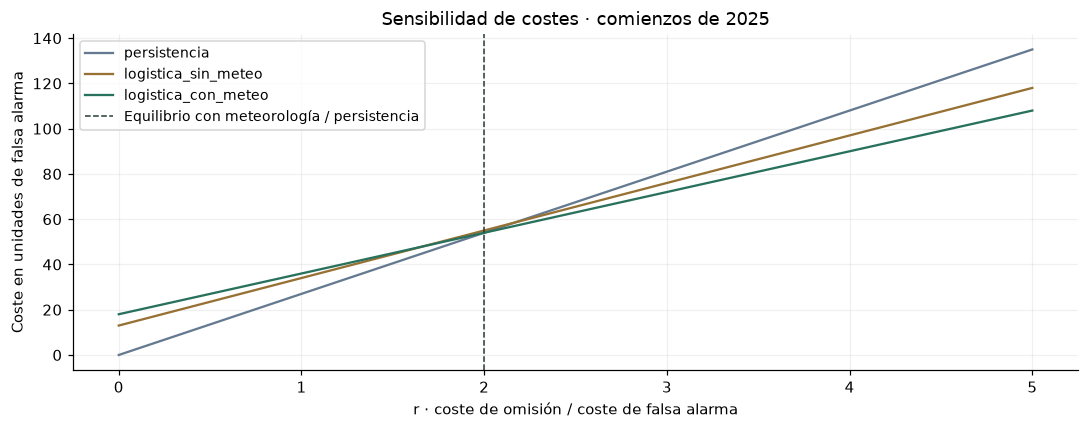

In [11]:
costs = pd.DataFrame(scenario_costs(counts))
cost_table = costs.pivot(index="escenario", columns="modelo", values="coste_simulado_unidades")
display(cost_table)
ratios = np.linspace(0, 5, 101)
fig, ax = plt.subplots()
colors = {"persistencia": "#657a90", "logistica_sin_meteo": "#977134", "logistica_con_meteo": "#28715c"}
for row in counts:
    ax.plot(ratios, row["falsas_alarmas"] + ratios * row["inicios_omitidos"],
            label=row["modelo"], color=colors[row["modelo"]])
ax.axvline(2, color="#263a36", linestyle="--", linewidth=1, label="Equilibrio con meteorología / persistencia")
ax.set(xlabel="r · coste de omisión / coste de falsa alarma",
       ylabel="Coste en unidades de falsa alarma",
       title="Sensibilidad de costes · comienzos de 2025")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 10. Situar el complemento sanitario

El análisis sanitario tiene otra escala, por provincia y año, y un objetivo de tasa de altas
respiratorias por cada 100.000 habitantes. Sus resultados exploratorios comparan historial,
demografía y PM10. La interpretación debe considerar la cobertura territorial, la agregación y
el tamaño de la muestra. Consulta [diseño y sensibilidad](../docs/09_demografia_y_comparacion_inicial.md).

In [12]:
health_metrics = pd.read_csv(ROOT / "data/interim/initial_comparison/metricas.csv")
display(health_metrics)

,escenario,modelo,n,mae,mse,rmse
0,red_constante,persistencia,58,136.207,"24,542.276",156.660
1,red_constante,ridge_demografia,58,163.519,"35,538.959",188.518
2,red_constante,ridge_demografia_pm10,58,164.712,"35,949.835",189.604
3,sin_alertas_ubicacion_area,persistencia,54,136.037,"24,521.815",156.594
4,sin_alertas_ubicacion_area,ridge_demografia,54,160.245,"34,788.769",186.517
5,sin_alertas_ubicacion_area,ridge_demografia_pm10,54,160.344,"34,796.899",186.539


## 11. Cómo interpretar y presentar los resultados

Ridge mejora modestamente el error global frente a persistencia en 2024. En el subconjunto de
días elevados la persistencia obtuvo menor MAE. El episodio de octubre permite ver que la
media del error oculta infraestimaciones importantes.

En clasificación de 2025, la meteorología detectó tres comienzos adicionales frente a la
logística base, acompañados de cinco falsas alarmas adicionales en el contexto de comienzos.
La utilidad depende de la relación entre los costes de ambos errores y la muestra incluye 27 comienzos.

La preparación conserva los huecos y excluye las filas incompletas. Por ello se deben informar
las métricas junto a la cobertura. El diseño retrospectivo usa históricos revisados y supone
disponibilidad inmediata del resumen diario. La
[propuesta de producción](../docs/32_propuesta_produccion_pm10.md) describe las comprobaciones
de latencia y la adaptación de variables que necesitaría una emisión anterior al día objetivo.

### Preguntas para comprobar tu comprensión

1. ¿Por qué una medición ausente puede eliminar varios ejemplos supervisados?
2. ¿Qué cambiaría si ajustásemos el escalador usando también las fechas de validación?
3. ¿Por qué un coeficiente de Ridge y una importancia del bosque necesitan interpretaciones diferentes?
4. ¿Qué muestra el caso de octubre que no vemos en un único MAE global?
5. ¿Cómo justificarías el coste relativo de omitir un comienzo con una organización real?

El código de entrenamiento de este recorrido trabaja en memoria. Las celdas leen los archivos del
proyecto y guardan sus salidas dentro del notebook al guardar o ejecutar el documento.